In [5]:
import pandas as pd
import numpy as np
import os
from pathlib import Path

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.svm import LinearSVC

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

In [7]:
DATA_DIR = r"F:\EDAIC-WOZ\data"
LABEL_DIR = r"F:\EDAIC-WOZ\labels"

print("Data directory:", DATA_DIR)
print("Label directory:", LABEL_DIR)
print("Data folder exists:", os.path.exists(DATA_DIR))
print("Label folder exists:", os.path.exists(LABEL_DIR))

Data directory: F:\EDAIC-WOZ\data
Label directory: F:\EDAIC-WOZ\labels
Data folder exists: True
Label folder exists: True


In [9]:
train_labels = pd.read_csv(
    os.path.join(LABEL_DIR, "train_split.csv")
)

print("Train shape:", train_labels.shape)
print("\nColumns:")
print(train_labels.columns.tolist())

print("\nFirst 5 rows:")
display(train_labels.head())

Train shape: (163, 6)

Columns:
['Participant_ID', 'Gender', 'PHQ_Binary', 'PHQ_Score', 'PCL-C (PTSD)', 'PTSD Severity']

First 5 rows:


,Participant_ID,Gender,PHQ_Binary,PHQ_Score,PCL-C (PTSD),PTSD Severity
0,302,male,0,4,0,28
1,303,female,0,0,0,17
2,304,female,0,6,0,20
3,305,male,0,7,0,28
4,307,female,0,4,0,23


In [11]:
print("PHQ_Binary class distribution:")
print(train_labels["PHQ_Binary"].value_counts().sort_index())

print("\nClass percentages:")
print(
    train_labels["PHQ_Binary"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

PHQ_Binary class distribution:
PHQ_Binary
0    126
1     37
Name: count, dtype: int64

Class percentages:
PHQ_Binary
0    77.3
1    22.7
Name: proportion, dtype: float64


In [41]:
def extract_egemaps(pid):
    pid = int(pid)

    feature_path = os.path.join(
        DATA_DIR,
        f"{pid:03d}_P",
        "features",
        f"{pid:03d}_BoAW_openSMILE_2.3.0_eGeMAPS.csv"
    )

    df = pd.read_csv(
        feature_path,
        header=None
    )

    # Remove first 2 metadata columns
    features = df.iloc[:, 2:]

    # Mean of each feature across all frames
    mean_features = features.mean(axis=0)

    # Standard deviation of each feature across all frames
    std_features = features.std(axis=0)

    # Combine mean and standard deviation
    participant_features = np.concatenate([
        mean_features.values,
        std_features.values
    ])

    return participant_features

In [43]:
X_list = []
y_list = []
participant_ids = []

for _, row in train_labels.iterrows():
    pid = row["Participant_ID"]

    try:
        features = extract_egemaps(pid)

        X_list.append(features)
        y_list.append(row["PHQ_Binary"])
        participant_ids.append(pid)

    except Exception as e:
        print(f"Error for participant {pid}: {e}")

X = np.array(X_list)
y = np.array(y_list)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (163, 200)
y shape: (163,)


In [45]:
print("Missing values in X:", np.isnan(X).sum())
print("Infinite values in X:", np.isinf(X).sum())

print("\nX dtype:", X.dtype)
print("y dtype:", y.dtype)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Missing values in X: 0
Infinite values in X: 0

X dtype: float64
y dtype: int32

X shape: (163, 200)
y shape: (163,)


In [93]:
model = Pipeline([

    ("selector", SelectKBest(
        score_func=f_classif,
        k=10
    )),

    ("scaler", StandardScaler()),

    ("svm", LinearSVC(
        class_weight="balanced",
        max_iter=5000,
        random_state=42
    ))
])

print(model)

Pipeline(steps=[('selector', SelectKBest()), ('scaler', StandardScaler()),
                ('svm',
                 LinearSVC(class_weight='balanced', max_iter=5000,
                           random_state=42))])


In [95]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [97]:
scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("5-Fold F1 Scores:")
for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.4f}")

5-Fold F1 Scores:
Fold 1: 0.3333
Fold 2: 0.1333
Fold 3: 0.4167
Fold 4: 0.3000
Fold 5: 0.3478


In [99]:
mean_f1 = scores.mean()
std_f1 = scores.std()

print("=" * 45)
print(f"Mean F1: {mean_f1:.4f}")
print(f"Std F1:  {std_f1:.4f}")
print(f"F1 Score: {mean_f1:.4f} ± {std_f1:.4f}")
print("=" * 45)

Mean F1: 0.3062
Std F1:  0.0944
F1 Score: 0.3062 ± 0.0944


In [101]:
from sklearn.model_selection import cross_val_predict

In [103]:
oof_predictions = cross_val_predict(
    model,
    X,
    y,
    cv=cv
)

print("Out-of-fold predictions shape:", oof_predictions.shape)
print("\nClassification Report:")
print(classification_report(
    y,
    oof_predictions,
    target_names=["Non-Depressed", "Depressed"]
))

Out-of-fold predictions shape: (163,)

Classification Report:
               precision    recall  f1-score   support

Non-Depressed       0.79      0.59      0.67       126
    Depressed       0.25      0.46      0.32        37

     accuracy                           0.56       163
    macro avg       0.52      0.52      0.50       163
 weighted avg       0.66      0.56      0.59       163



Confusion Matrix:
[[74 52]
 [20 17]]


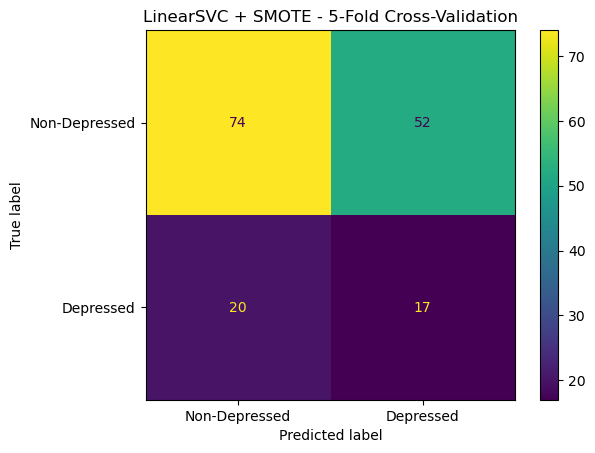

In [105]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y,
    oof_predictions
)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-Depressed", "Depressed"]
)

disp.plot()
plt.title("LinearSVC + SMOTE - 5-Fold Cross-Validation")
plt.show()

In [107]:
final_results = {
    "Model": "LinearSVC + SMOTE",
    "Features": "eGeMAPS",
    "Selected Features": 10,
    "CV Folds": 5,
    "Mean F1": mean_f1,
    "Std F1": std_f1,
    "Accuracy": accuracy_score(y, oof_predictions),
    "Depressed Precision": precision_score(y, oof_predictions),
    "Depressed Recall": recall_score(y, oof_predictions),
    "Depressed F1": f1_score(y, oof_predictions)
}

results_df = pd.DataFrame([final_results])

display(results_df)


,Model,Features,Selected Features,CV Folds,Mean F1,Std F1,Accuracy,Depressed Precision,Depressed Recall,Depressed F1
0,LinearSVC + SMOTE,eGeMAPS,10,5,0.306232,0.094439,0.558282,0.246377,0.459459,0.320755


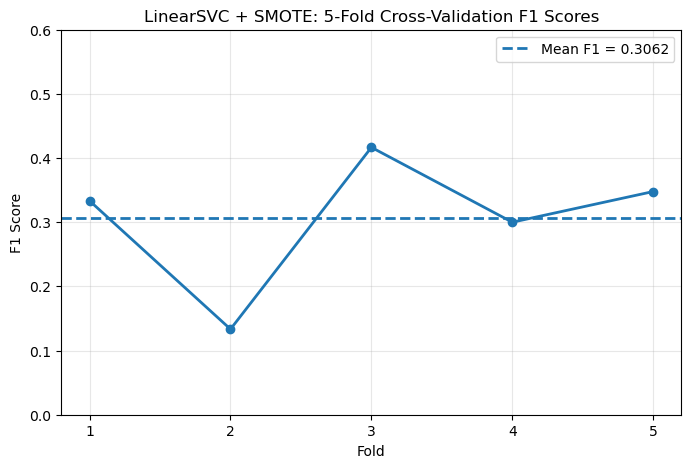

In [109]:
import matplotlib.pyplot as plt

fold_numbers = [1, 2, 3, 4, 5]

plt.figure(figsize=(8, 5))

plt.plot(
    fold_numbers,
    scores,
    marker="o",
    linewidth=2
)

plt.axhline(
    mean_f1,
    linestyle="--",
    linewidth=2,
    label=f"Mean F1 = {mean_f1:.4f}"
)

plt.xlabel("Fold")
plt.ylabel("F1 Score")
plt.title("LinearSVC + SMOTE: 5-Fold Cross-Validation F1 Scores")

plt.xticks(fold_numbers)
plt.ylim(0, 0.6)
plt.grid(True, alpha=0.3)
plt.legend()

plt.show()

In [111]:
from sklearn import set_config

set_config(display="diagram")

model

Pipeline(steps=[('selector', SelectKBest()), ('scaler', StandardScaler()),
                ('svm',
                 LinearSVC(class_weight='balanced', max_iter=5000,
                           random_state=42))])

In [113]:

scores = cross_val_score(
    model,
    X,
    y,
    cv=cv,
    scoring="f1"
)

print("5-Fold F1 Scores:")
for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nMean F1: {scores.mean():.4f}")
print(f"Std F1: {scores.std():.4f}")

5-Fold F1 Scores:
Fold 1: 0.3333
Fold 2: 0.1333
Fold 3: 0.4167
Fold 4: 0.3000
Fold 5: 0.3478

Mean F1: 0.3062
Std F1: 0.0944
